<a href="https://colab.research.google.com/github/asheta66/Medical-Applications-Alzheimer-s-Disease-/blob/main/Alzheimers_Classification_Revised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Revised Alzheimer’s disease status benchmark

Place the original unresampled `alzheimers_disease_data.csv` beside this notebook and run all cells in order. Dependencies are pandas, NumPy, SciPy, matplotlib, seaborn, scikit-learn, and imbalanced-learn. Graphviz and the `dot` executable are optional. Results are written to `revision_results/` (the original descriptive Statistics.png is saved beside the notebook). The target is the dataset's binary Diagnosis label. The primary configuration is fixed before evaluating the holdout. Ablations use training-only cross-validation.


In [5]:
# Importing the libraries
import math
import numpy as np
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_style("whitegrid")

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from matplotlib import pyplot as plt

In [6]:
# !apt install texlive-xetex texlive-fonts-recommended texlive-generic-recommended
# !apt install cm-super

In [7]:
# plt.rcParams['text.usetex'] = True

**Reading the data**

In [8]:
# Importing the datasets
df     = pd.read_csv('alzheimers_disease_data.csv')
source_counts = df['Diagnosis'].value_counts()


**Display the data**

In [9]:
df.shape

(2149, 34)

**Display sample data**

In [10]:
df.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,6.518877,0,0,1.725883,0,0,0,1,0,0
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,7.118696,0,0,2.592424,0,0,0,0,1,0
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,5.895077,0,0,7.119548,0,1,0,1,0,0
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,8.965106,0,1,6.481226,0,0,0,0,0,0
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,6.045039,0,0,0.014691,0,0,1,1,0,0


In [11]:
df.sample(n = 10)

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
768,5519,78,1,1,0,20.359343,1,5.256781,8.747961,6.297251,...,3.957904,0,0,7.458042,0,0,0,0,0,0
2043,6794,77,1,0,2,23.651759,1,12.820735,9.723538,3.817408,...,3.309767,0,0,4.481021,0,0,0,0,0,0
771,5522,62,0,0,2,27.768115,0,12.727994,5.530183,9.896332,...,9.292582,0,0,4.512444,0,0,0,1,0,0
808,5559,83,0,0,1,17.467626,0,8.131463,7.851118,5.051645,...,1.734994,0,1,3.809386,0,0,0,1,0,1
2082,6833,60,1,0,1,37.089995,0,6.879326,3.611449,0.016446,...,4.160138,1,0,2.273081,0,1,1,0,0,0
470,5221,75,1,1,1,25.691361,0,3.078179,9.089393,6.199063,...,7.959887,0,0,5.967555,0,0,0,1,0,0
1522,6273,77,0,0,1,26.828226,0,8.513876,5.538150,0.047509,...,2.535404,0,0,3.903632,0,1,0,0,1,1
712,5463,67,1,3,2,19.639042,0,4.103412,0.233413,0.361957,...,9.718999,0,0,5.652948,1,0,0,0,0,0
476,5227,74,0,3,2,21.148124,1,7.484445,0.166582,5.966973,...,5.317654,1,0,6.755856,0,0,0,0,0,0
1620,6371,87,1,0,3,27.012602,0,3.428322,5.315698,5.141243,...,1.902217,0,0,1.033813,0,1,0,0,0,0


In [12]:
# Drop the DoctorInCharge column
# df.drop(columns='DoctorInCharge', inplace=True)

In [13]:
# Drop rows with any NaN values
required = df.columns.difference(['PatientID', 'DoctorInCharge'])
df = df.dropna(subset=required)
if 'PatientID' in df and df['PatientID'].isna().any():
    raise ValueError('Missing PatientID prevents checking for repeated identifiers.')

In [14]:
df.sample(n = 10)

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
1790,6541,63,1,0,3,37.077944,1,16.909751,5.699391,7.164247,...,0.283086,0,0,5.078330,0,0,0,1,0,0
1342,6093,80,1,0,1,30.511732,0,3.788271,6.144566,9.807208,...,4.801976,1,0,3.586542,0,0,0,0,0,1
766,5517,61,1,1,1,31.414055,0,14.254247,9.252043,0.937933,...,0.885236,0,1,8.638541,0,0,0,0,0,0
457,5208,68,0,0,3,26.634779,0,1.508775,3.019339,3.046509,...,5.380112,0,1,0.865189,0,0,0,1,1,1
1507,6258,82,1,0,0,32.912732,0,7.858106,7.495348,7.517459,...,8.702120,0,1,0.203655,0,0,0,0,0,1
838,5589,78,1,0,1,19.698489,0,14.402796,5.718099,3.096124,...,3.304945,0,0,3.844414,0,0,0,0,0,1
2128,6879,61,0,0,1,39.498186,0,3.207478,3.297674,4.372394,...,5.174030,1,0,7.988514,0,0,0,0,0,0
90,4841,74,0,3,1,26.428679,0,16.683678,5.369293,9.672834,...,5.492027,0,0,4.699102,0,1,0,1,0,0
1620,6371,87,1,0,3,27.012602,0,3.428322,5.315698,5.141243,...,1.902217,0,0,1.033813,0,1,0,0,0,0
1672,6423,72,0,0,1,19.112288,1,6.820456,7.565925,3.398981,...,6.453461,1,0,0.695730,0,1,0,0,0,0


In [15]:
ones_count = df['Diagnosis'].value_counts()[1]
print(ones_count)

760


In [16]:
zeros_count = (df['Diagnosis'] == 0).sum()
print(zeros_count)

1389


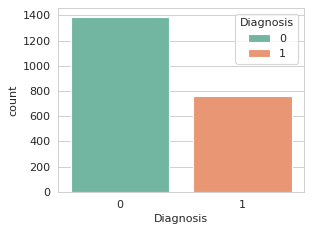

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with size 4x3 inches, 80 DPI resolution
fig = plt.figure(figsize=(4, 3), dpi=80)

# Use 'Diagnosis' as both x and hue to apply palette safely
sns.countplot(data=df, x='Diagnosis', hue='Diagnosis', palette='Set2')

plt.tight_layout()
plt.savefig('classes.png')
plt.show()

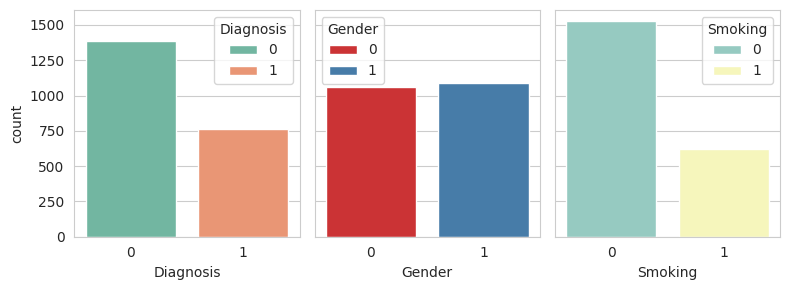

In [18]:
from matplotlib import pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(8, 3), sharey=True)

sns.countplot(ax=axes[0], data=df, x='Diagnosis', hue='Diagnosis', palette='Set2')
sns.countplot(ax=axes[1], data=df, x='Gender', hue='Gender', palette='Set1')
sns.countplot(ax=axes[2], data=df, x='Smoking', hue='Smoking', palette='Set3')

plt.tight_layout()
plt.savefig('Statistics.png', bbox_inches='tight')
plt.show()

In [19]:
# # Set up the matplotlib plot configuration
# f, ax = plt.subplots(figsize=(18, 4))
# # Generate a mask for upper traingle
# mask = np.triu(np.ones_like(corr, dtype=bool))
# # Configure a custom diverging colormap
# cmap = sns.diverging_palette(230, 20, as_cmap=True)
# # Draw the heatmap
# sns.heatmap(corr, annot=True, mask = mask, cmap=cmap)
# plt.savefig('Heatmap.png')

In [20]:
from imblearn.over_sampling import RandomOverSampler
SEED = 42

In [21]:
# # example of random undersampling to balance the class distribution
# from collections import Counter
# from sklearn.datasets import make_classification
# from imblearn.under_sampling import RandomUnderSampler
# from imblearn.over_sampling import RandomOverSampler

# # The class can be used just like the RandomOverSampler class in the
# # previous section, except the strategies impact the majority class
# # instead of the minority class. For example, setting the sampling_strategy
# # argument to “majority” will oversample the majority class determined
# # by the class with the largest number of examples.

# # define Oversample strategy
# oversample = RandomOverSampler(sampling_strategy='not majority')
# x_over, y_over = oversample.fit_resample(x_data,y_data)

In [22]:
# y_over.value_counts().plot.pie(autopct='%.2f')

In [23]:
# x_over.shape

In [24]:
# X

**Preparing data for machine learning classifier**



In [25]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Diagnosis', 'PatientID', 'DoctorInCharge'], errors='ignore')
y = df['Diagnosis']
if set(y.unique()) != {0, 1}:
    raise ValueError('Diagnosis must contain both binary labels 0 and 1.')
if 'PatientID' in df and not df['PatientID'].is_unique:
    raise ValueError('Repeated PatientID values require a patient-grouped split and cross-validation.')
if X.select_dtypes(exclude=['number', 'bool']).shape[1]:
    raise ValueError('Unexpected nonnumeric predictors. Check that the supplied CSV matches the documented dataset.')

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
assert x_train.index.intersection(x_test.index).empty
# Screen for identical predictor rows across partitions, independently of Diagnosis.
train_hashes = pd.util.hash_pandas_object(x_train, index=False)
test_hashes = pd.util.hash_pandas_object(x_test, index=False)
if test_hashes.isin(train_hashes).any():
    raise ValueError('Identical predictor rows cross partitions. Review duplicates and use grouped partitioning before evaluation.')


**Feature selection**

In [26]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
from sklearn.base import clone
from imblearn.pipeline import Pipeline
from pathlib import Path
import sklearn
import imblearn
import sys
import hashlib

out = Path('revision_results')
out.mkdir(exist_ok=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def abs_pearson(features, labels):
    # Absolute point-biserial association for a binary target.
    centered = features - features.mean(axis=0)
    target = labels - labels.mean()
    denominator = np.linalg.norm(centered, axis=0) * np.linalg.norm(target)
    return np.divide(np.abs(centered.T @ target), denominator,
                     out=np.zeros(features.shape[1]), where=denominator != 0)

def make_pipeline(estimator, selection='anova', oversample=True):
    selector = {'anova': SelectKBest(f_classif, k=5),
                'pearson': SelectKBest(abs_pearson, k=5),
                'all': 'passthrough'}[selection]
    sampler = RandomOverSampler(random_state=SEED) if oversample else 'passthrough'
    return Pipeline([('selection', selector), ('scaling', StandardScaler()),
                     ('oversampling', sampler), ('classifier', clone(estimator))])

# These two transforms reproduce the primary pipeline's preprocessing for
# the existing model cells. The untouched training rows are used for train metrics.
selector = SelectKBest(f_classif, k=5).fit(x_train, y_train)
selected_feature_names = x_train.columns[selector.get_support()].tolist()
sc = StandardScaler().fit(selector.transform(x_train))
primary_train = sc.transform(selector.transform(x_train))
primary_test = sc.transform(selector.transform(x_test))
fit_x, fit_y = RandomOverSampler(random_state=SEED).fit_resample(primary_train, y_train)


In [27]:
ranking = pd.DataFrame({'feature': x_train.columns,
                        'anova_f': selector.scores_,
                        'abs_pearson': abs_pearson(x_train.to_numpy(), y_train.to_numpy()),
                        'anova_top5': selector.get_support()})
pearson_selector = SelectKBest(abs_pearson, k=5).fit(x_train, y_train)
ranking['pearson_top5'] = pearson_selector.get_support()
ranking = ranking.sort_values('anova_f', ascending=False)
ranking.to_csv(out / 'feature_ranking.csv', index=False)
print('Selected Features:', selected_feature_names)
display(ranking)


Selected Features: ['MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL']


,feature,anova_f,abs_pearson,anova_top5,pearson_top5
23,FunctionalAssessment,257.318763,0.361017,True,True
26,ADL,219.327424,0.336556,True,True
24,MemoryComplaints,199.616266,0.322723,True,True
22,MMSE,101.512032,0.236266,True,True
25,BehavioralProblems,79.965086,0.210950,True,True
9,SleepQuality,5.240384,0.055161,False,False
20,CholesterolHDL,4.667156,0.052066,False,False
11,CardiovascularDisease,3.306843,0.043843,False,False
16,SystolicBP,3.168299,0.042917,False,False
21,CholesterolTriglycerides,2.863362,0.040803,False,False


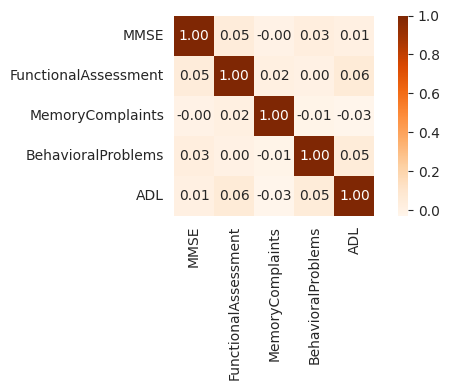

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the desired columns
cols = selected_feature_names

# Compute the correlation matrix
corr_matrix = x_train[cols].corr()

# Plot the heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='Oranges', fmt=".2f", square=True)

# Save the figure
plt.tight_layout()
plt.savefig(out / 'Selected_Feature_Correlations.png')
plt.show()

**Scaling the data**

In [29]:
counts = pd.DataFrame({
    'source_csv': source_counts, 'eligible_original': y.value_counts(),
    'original_train': y_train.value_counts(), 'original_test': y_test.value_counts(),
    'resampled_train': pd.Series(fit_y).value_counts()
}).reindex([0, 1], fill_value=0).fillna(0).astype(int)
counts.loc['Total'] = counts.sum()
counts.to_csv(out / 'partition_counts.csv', index_label='Diagnosis')
display(counts)


,source_csv,eligible_original,original_train,original_test,resampled_train
Diagnosis,,,,,
0,1389,1389,1111,278,1111
1,760,760,608,152,1111
Total,2149,2149,1719,430,2222


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def calculate_confusion(clf_name, y_train, y_pred_train, y_test, y_pred_test):

    # Calculate accuracy, precision, recall, and F1 score for training and testing sets
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)
    train_prec = precision_score(y_train, y_pred_train)
    test_prec = precision_score(y_test, y_pred_test)
    train_rec = recall_score(y_train, y_pred_train)
    test_rec = recall_score(y_test, y_pred_test)
    train_f1 = f1_score(y_train, y_pred_train)
    test_f1 = f1_score(y_test, y_pred_test)

    # Calculate the confusion matrix for training and testing sets
    train_cm = confusion_matrix(y_train, y_pred_train)
    test_cm = confusion_matrix(y_test, y_pred_test)

    # Create a 1x2 figure with the confusion matrix on the left and evaluation metrics on the right
    fig, axs = plt.subplots(1, 2, figsize=(6,2),sharey=True)

    # Plot the confusion matrix for training set
    sns.heatmap(train_cm, annot=True, cmap='YlGnBu', fmt='g', ax=axs[0], annot_kws={"size": 12}, cbar_kws={"shrink": 0.7})
    axs[0].set_title('Training Set',fontsize=10)
    axs[0].set_xlabel('Predicted Labels',fontsize=10)
    axs[0].set_ylabel('True Labels',fontsize=10)

    # Plot the confusion matrix for testing set
    sns.heatmap(test_cm, annot=True, cmap='YlGnBu', fmt='g', ax=axs[1], annot_kws={"size": 12}, cbar_kws={"shrink": 0.7})
    axs[1].set_title('Testing Set',fontsize=10)
    axs[1].set_xlabel('Predicted Labels',fontsize=10)
    axs[1].set_ylabel('True Labels',fontsize=10)

    # Add a main title to the figure
    # fig.suptitle(f'Confusion matrix using {clf_name} ', fontsize=12, y=1.01, fontname='Times')
    # fig.suptitle(f'Confusion matrix using {clf_name} ', fontsize=12, y=1.09)
    plt.savefig(out / (clf_name + ".png"), bbox_inches="tight")
    # Show the plot
    plt.show()

    # Define the performance metrics for training and testing cases
    train_metrics = ["Train Accuracy", "Train Precision", "Train Recall", "Train F1"]
    test_metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]

    # Create a list of lists containing the metrics
    table = [train_metrics + test_metrics,
         [train_acc, train_prec, train_rec, train_f1, test_acc, test_prec, test_rec, test_f1]]

    # Print the table
    print('-----Results for',clf_name,'----------------------')
    display(pd.DataFrame(table[1:], columns=table[0]))
primary_models = {}
primary_metrics = []
predictions = pd.DataFrame({'csv_row_index': y_test.index, 'Diagnosis': y_test.to_numpy()})

def record_model(name, estimator, y_pred_train, y_pred_test):
    primary_models[name] = estimator
    scores = estimator.predict_proba(primary_test)[:, 1]
    predictions[name + '_prediction'] = y_pred_test
    predictions[name + '_score'] = scores
    calculate_confusion(name, y_train, y_pred_train, y_test, y_pred_test)
    for partition, truth, labels, probabilities in [
        ('train_original', y_train, y_pred_train, estimator.predict_proba(primary_train)[:, 1]),
        ('test_original', y_test, y_pred_test, scores)
    ]:
        tn, fp, fn, tp = confusion_matrix(truth, labels, labels=[0, 1]).ravel()
        primary_metrics.append(dict(model=name, partition=partition,
            n=len(truth), correct=int(tn + tp), tn=tn, fp=fp, fn=fn, tp=tp,
            accuracy=accuracy_score(truth, labels),
            balanced_accuracy=balanced_accuracy_score(truth, labels),
            precision=precision_score(truth, labels, zero_division=0),
            sensitivity=recall_score(truth, labels, zero_division=0),
            specificity=tn / (tn + fp), f1=f1_score(truth, labels, zero_division=0),
            mcc=matthews_corrcoef(truth, labels), auroc=roc_auc_score(truth, probabilities)))
    return roc_curve(y_test, scores)[:2] + (roc_auc_score(y_test, scores),)


# Logistic Regression

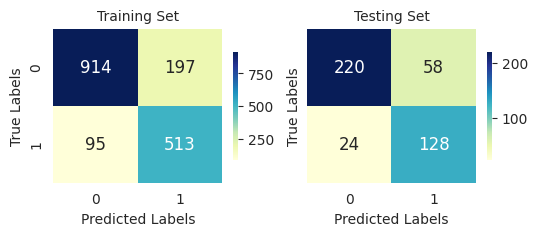

-----Results for LR ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.830134,0.722535,0.84375,0.778452,0.809302,0.688172,0.842105,0.757396


In [31]:
#set up plotting area
from matplotlib.pyplot import figure
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

#LogisticRegression ####################################
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(solver='liblinear', max_iter=20, random_state=SEED)
lr.fit(fit_x, fit_y)
y_pred_train = lr.predict(primary_train)
y_pred_test  = lr.predict(primary_test)
fpr1, tpr1, auc1 = record_model("LR", lr, y_pred_train, y_pred_test)


# Support Vector Machine

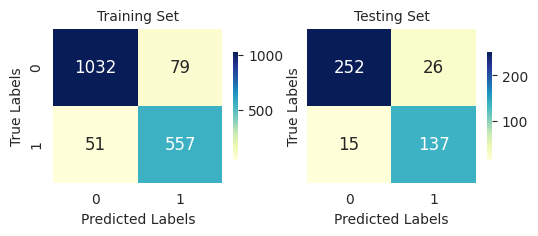

-----Results for SVM ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.924375,0.875786,0.916118,0.895498,0.904651,0.840491,0.901316,0.869841


In [32]:
#SVM ####################################
from sklearn.svm import SVC
svm = SVC(kernel='rbf', C=1.0, probability=True, random_state=SEED)
svm.fit(fit_x, fit_y)
y_pred_train = svm.predict(primary_train)
y_pred_test  = svm.predict(primary_test)
fpr2, tpr2, auc2 = record_model("SVM", svm, y_pred_train, y_pred_test)


# Gradient Boosting Classifier

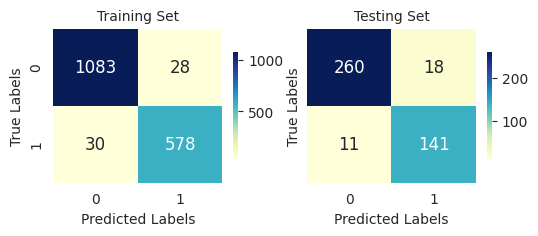

-----Results for GBC ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.966259,0.953795,0.950658,0.952224,0.932558,0.886792,0.927632,0.906752


In [33]:
#GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

GBC = GradientBoostingClassifier(random_state=1)
GBC.fit(fit_x, fit_y)
y_pred_train = GBC.predict(primary_train)
y_pred_test  = GBC.predict(primary_test)

fpr3, tpr3, auc3 = record_model("GBC", GBC, y_pred_train, y_pred_test)


# GaussianNB

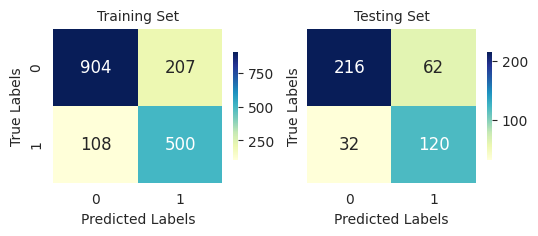

-----Results for GNB ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.816754,0.707214,0.822368,0.760456,0.781395,0.659341,0.789474,0.718563


In [34]:
#GaussianNB
from sklearn.metrics import precision_score
from sklearn.naive_bayes import GaussianNB

GNB = GaussianNB(priors=None, var_smoothing=1e-9)
GNB.fit(fit_x, fit_y)

y_pred_train = GNB.predict(primary_train)
y_pred_test = GNB.predict(primary_test)
fpr4, tpr4, auc4 = record_model("GNB", GNB, y_pred_train, y_pred_test)


# KNeighborsClassifier

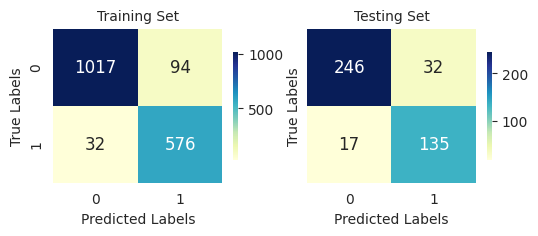

-----Results for KNC ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.926702,0.859701,0.947368,0.901408,0.886047,0.808383,0.888158,0.846395


In [35]:
# KNN Model
from sklearn.neighbors import KNeighborsClassifier
KNC = KNeighborsClassifier()
KNC.fit(fit_x, fit_y)
y_pred_train = KNC.predict(primary_train)
y_pred_test  = KNC.predict(primary_test)
fpr5, tpr5, auc5 = record_model("KNC", KNC, y_pred_train, y_pred_test)


# Decision Tree

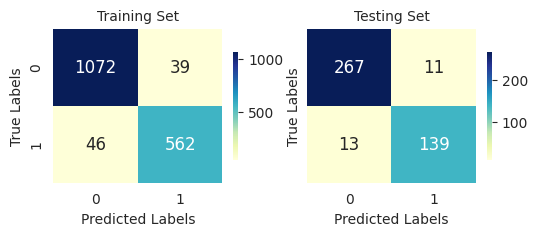

-----Results for DT ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.950553,0.935108,0.924342,0.929694,0.944186,0.926667,0.914474,0.92053


In [36]:
# Decision Tree Model
from sklearn import tree
DT = tree.DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=None,ccp_alpha=0.01, random_state=SEED)
DT.fit(fit_x, fit_y)
y_pred_train = DT.predict(primary_train)
y_pred_test  = DT.predict(primary_test)
fpr6, tpr6, auc6 = record_model("DT", DT, y_pred_train, y_pred_test)


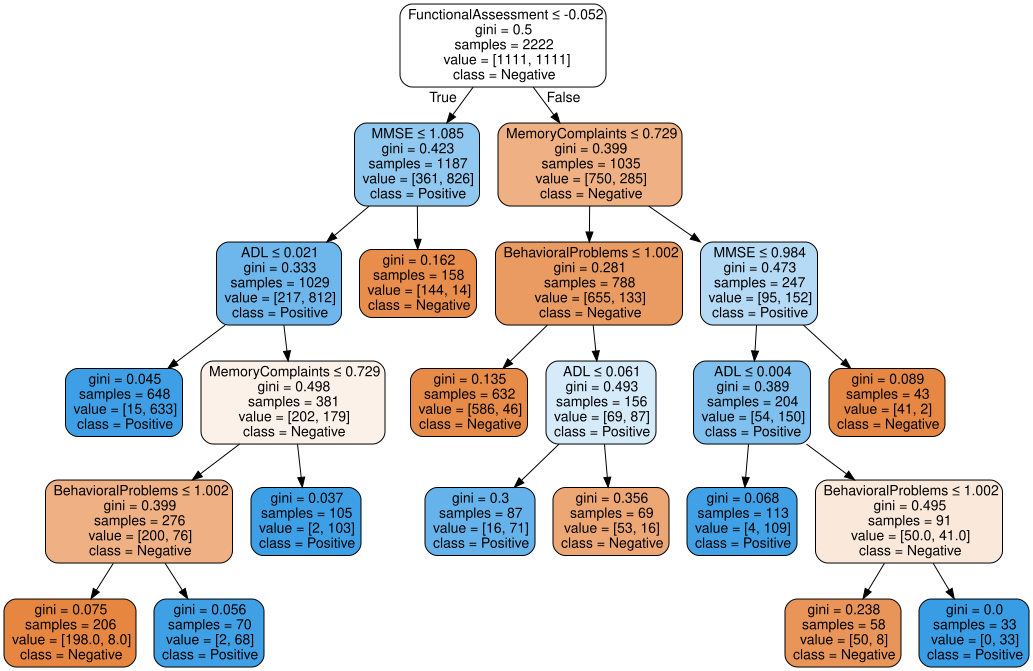

In [37]:
# Visualize the fitted benchmark model when Graphviz is available.
from sklearn.tree import export_graphviz
from importlib.util import find_spec
from shutil import which

if find_spec('graphviz') and which('dot'):
    import graphviz
    dot_data = export_graphviz(DT, out_file=None, feature_names=selected_feature_names,
                               class_names=['Negative', 'Positive'], filled=True, rounded=True,
                               special_characters=True)
    graph = graphviz.Source(dot_data)
    graph.render(str(out / 'decision_tree'), format='png', cleanup=True)
    display(graph)
else:
    print('Optional Graphviz diagram skipped. Install graphviz and dot to render it.')


In [38]:
# Plotting the Decision Tree diagram
# from sklearn.tree import plot_tree
# plt.figure(figsize=(4,4))
# plot_tree(DT, filled=True, feature_names=selected_feature_names, class_names='Diagnosis')
# plt.show()

# Random Forest Classifier

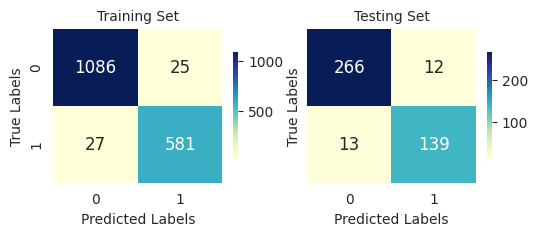

-----Results for RFC ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.96975,0.958746,0.955592,0.957166,0.94186,0.92053,0.914474,0.917492


In [39]:
#RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
# Use the original Random Forest settings.
RFC = RandomForestClassifier(n_estimators=100, max_depth=7, criterion='gini', max_features=1.0, random_state=42)
RFC.fit(fit_x, fit_y)
y_pred_train = RFC.predict(primary_train)
y_pred_test  = RFC.predict(primary_test)
fpr7, tpr7, auc7 = record_model("RFC", RFC, y_pred_train, y_pred_test)


In [40]:
# Print the depths of the fitted benchmark forest.
for i, estimator in enumerate(RFC.estimators_):
    print(f'Tree {i}: {estimator.tree_.max_depth}')


Tree 0: 7
Tree 1: 7
Tree 2: 7
Tree 3: 7
Tree 4: 7
Tree 5: 7
Tree 6: 7
Tree 7: 7
Tree 8: 7
Tree 9: 7
Tree 10: 7
Tree 11: 7
Tree 12: 7
Tree 13: 7
Tree 14: 7
Tree 15: 7
Tree 16: 7
Tree 17: 7
Tree 18: 7
Tree 19: 7
Tree 20: 7
Tree 21: 7
Tree 22: 7
Tree 23: 7
Tree 24: 7
Tree 25: 7
Tree 26: 7
Tree 27: 7
Tree 28: 7
Tree 29: 7
Tree 30: 7
Tree 31: 7
Tree 32: 7
Tree 33: 7
Tree 34: 7
Tree 35: 7
Tree 36: 7
Tree 37: 7
Tree 38: 7
Tree 39: 7
Tree 40: 7
Tree 41: 7
Tree 42: 7
Tree 43: 7
Tree 44: 7
Tree 45: 7
Tree 46: 7
Tree 47: 7
Tree 48: 7
Tree 49: 7
Tree 50: 7
Tree 51: 7
Tree 52: 7
Tree 53: 7
Tree 54: 7
Tree 55: 7
Tree 56: 7
Tree 57: 7
Tree 58: 7
Tree 59: 7
Tree 60: 7
Tree 61: 7
Tree 62: 7
Tree 63: 7
Tree 64: 7
Tree 65: 7
Tree 66: 7
Tree 67: 7
Tree 68: 7
Tree 69: 7
Tree 70: 7
Tree 71: 7
Tree 72: 7
Tree 73: 7
Tree 74: 7
Tree 75: 7
Tree 76: 7
Tree 77: 7
Tree 78: 7
Tree 79: 7
Tree 80: 7
Tree 81: 7
Tree 82: 7
Tree 83: 7
Tree 84: 7
Tree 85: 7
Tree 86: 7
Tree 87: 7
Tree 88: 7
Tree 89: 7
Tree 90: 7
Tree 91: 

In [41]:
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.tree import plot_tree
# import matplotlib.pyplot as plt

# # Assuming you have trained your RandomForestClassifier and named it RFC
# # Make sure to replace RFC with your actual RandomForestClassifier instance

# # Check if the RFC has been fitted and contains estimators
# if hasattr(RFC, 'estimators_') and len(RFC.estimators_) > 0:
#     # Choose the best tree from the forest based on mean decrease impurity
#     best_tree_index = RFC.feature_importances_.argmax()

#     # Verify that the best_tree_index is within valid range
#     if 0 <= best_tree_index < len(RFC.estimators_):
#         # Plot the best tree in the forest
#         fig, ax = plt.subplots(figsize=(10, 10))
#         plot_tree(RFC.estimators_[best_tree_index], ax=ax)
#         plt.show()
#     else:
#         print("Invalid best_tree_index.")
# else:
#     print("RandomForestClassifier not properly fitted.")


In [42]:
print(selected_feature_names)

['MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL']


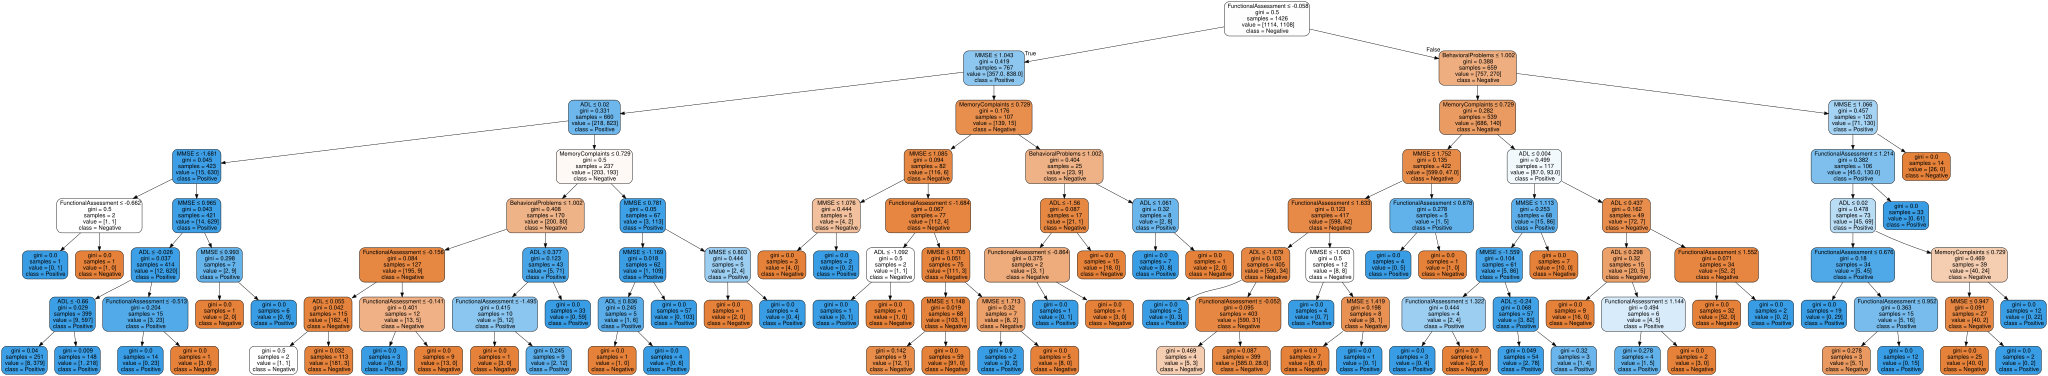

In [43]:
# Visualize the fitted benchmark model when Graphviz is available.
from sklearn.tree import export_graphviz
from importlib.util import find_spec
from shutil import which

if find_spec('graphviz') and which('dot'):
    import graphviz
    dot_data = export_graphviz(RFC.estimators_[0], out_file=None, feature_names=selected_feature_names,
                               class_names=['Negative', 'Positive'], filled=True, rounded=True,
                               special_characters=True)
    graph = graphviz.Source(dot_data)
    graph.render(str(out / 'random_forest_tree'), format='png', cleanup=True)
    display(graph)
else:
    print('Optional Graphviz diagram skipped. Install graphviz and dot to render it.')


# Artificial Neural Network

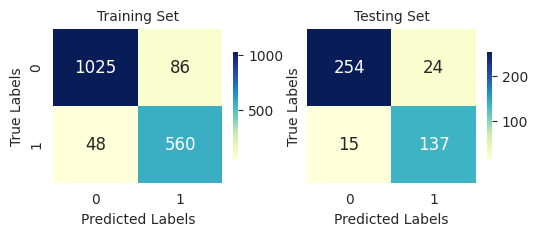

-----Results for ANN ----------------------


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.922048,0.866873,0.921053,0.893142,0.909302,0.850932,0.901316,0.875399


In [44]:
#Artificial Neural Network
from sklearn.neural_network import MLPClassifier
ANN = MLPClassifier(solver='adam', max_iter= 1000, alpha=1e-5,hidden_layer_sizes=(5, 2), random_state=1)
ANN.fit(fit_x, fit_y)
y_pred_train = ANN.predict(primary_train)
y_pred_test  = ANN.predict(primary_test)
fpr8, tpr8, auc8 = record_model("ANN", ANN, y_pred_train, y_pred_test)


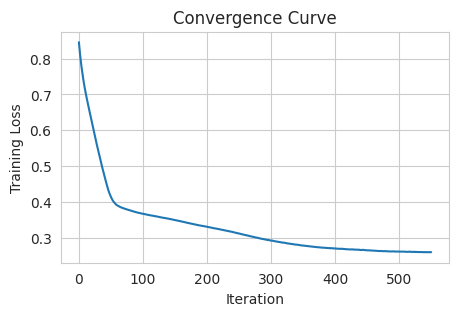

In [45]:
# Get the training loss values at each iteration
loss_values = ANN.loss_curve_

fig = plt.figure(figsize=(5,3))
# Plot the convergence curve
plt.plot(loss_values)
plt.grid(True)
plt.title('Convergence Curve')
plt.xlabel('Iteration', fontsize=10)
plt.ylabel('Training Loss', fontsize=10)
plt.savefig('ANN_convergence.png')
plt.savefig(out / 'ANN_training_loss.png', bbox_inches='tight')
plt.show()

## Training-only ablations and paired holdout comparison

In [46]:
from sklearn.model_selection import cross_validate
from scipy.stats import binomtest
import json

configurations = [
    ('anova', True), ('anova', False), ('all', True), ('all', False),
    ('pearson', True), ('pearson', False)
]
rows = []
results = []
for name, estimator in primary_models.items():
    for selection, oversample in configurations:
        scores = cross_validate(
            make_pipeline(estimator, selection, oversample), x_train, y_train, cv=cv,
            scoring=['accuracy', 'balanced_accuracy', 'roc_auc', 'f1'],
            error_score='raise'
        )
        if selection == 'anova' and oversample:
            results.append(scores['test_accuracy'])
        for fold in range(cv.get_n_splits()):
            rows.append(dict(model=name, selection=selection, oversampling=oversample,
                             fold=fold+1, **{key[5:]: values[fold]
                             for key, values in scores.items() if key.startswith('test_')}))
fold_scores = pd.DataFrame(rows)
fold_scores.to_csv(out / 'ablation_cv_folds.csv', index=False)
summary = fold_scores.groupby(['model', 'selection', 'oversampling'])[
    ['accuracy', 'balanced_accuracy', 'roc_auc', 'f1']].agg(['mean', 'std'])
summary.columns = ['_'.join(column) for column in summary.columns]
summary.to_csv(out / 'ablation_cv_summary.csv')

pd.DataFrame(primary_metrics).to_csv(out / 'primary_metrics.csv', index=False)
predictions.to_csv(out / 'holdout_predictions.csv', index=False)
rf_correct = predictions['RFC_prediction'].eq(predictions['Diagnosis']).to_numpy()
gbc_correct = predictions['GBC_prediction'].eq(predictions['Diagnosis']).to_numpy()
rf_only = int((rf_correct & ~gbc_correct).sum())
gbc_only = int((gbc_correct & ~rf_correct).sum())
paired_difference = rf_correct.astype(int) - gbc_correct.astype(int)
rng = np.random.default_rng(SEED)
draws = rng.integers(len(paired_difference), size=(10000, len(paired_difference)))
ci_low, ci_high = np.quantile(paired_difference[draws].mean(axis=1), [0.025, 0.975])
comparison = {
    'n_test': len(predictions), 'rf_correct': int(rf_correct.sum()),
    'gbc_correct': int(gbc_correct.sum()), 'rf_only_correct': rf_only,
    'gbc_only_correct': gbc_only, 'accuracy_delta_rf_minus_gbc': paired_difference.mean(),
    'paired_bootstrap_95pct_low': ci_low, 'paired_bootstrap_95pct_high': ci_high,
    'mcnemar_exact_two_sided_p': (
        binomtest(rf_only, rf_only + gbc_only, 0.5).pvalue if rf_only + gbc_only else 1.0)
}
pd.DataFrame([comparison]).to_csv(out / 'rf_gbc_paired_comparison.csv', index=False)
display(pd.DataFrame(primary_metrics).query("partition == 'test_original'"))
display(summary)
display(pd.DataFrame([comparison]))
metadata = {
    'seed': SEED, 'test_fraction': 0.2, 'training_cv_folds': cv.get_n_splits(),
    'source_sha256': hashlib.sha256(Path('alzheimers_disease_data.csv').read_bytes()).hexdigest(),
    'python': sys.version, 'scikit_learn': sklearn.__version__,
    'imbalanced_learn': imblearn.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
    'model_parameters': {name: model.get_params() for name, model in primary_models.items()}
}
(out / 'run_metadata.json').write_text(json.dumps(metadata, indent=2))


,model,partition,n,correct,tn,fp,fn,tp,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,mcc,auroc
1,LR,test_original,430,348,220,58,24,128,0.809302,0.816736,0.688172,0.842105,0.791367,0.757396,0.611252,0.886407
3,SVM,test_original,430,389,252,26,15,137,0.904651,0.903895,0.840491,0.901316,0.906475,0.869841,0.795964,0.934092
5,GBC,test_original,430,401,260,18,11,141,0.932558,0.931442,0.886792,0.927632,0.935252,0.906752,0.854502,0.949948
7,GNB,test_original,430,336,216,62,32,120,0.781395,0.783226,0.659341,0.789474,0.776978,0.718563,0.548082,0.861771
9,KNC,test_original,430,381,246,32,17,135,0.886047,0.886525,0.808383,0.888158,0.884892,0.846395,0.758256,0.923005
11,DT,test_original,430,406,267,11,13,139,0.944186,0.937453,0.926667,0.914474,0.960432,0.920530,0.877568,0.939074
13,RFC,test_original,430,405,266,12,13,139,0.941860,0.935654,0.920530,0.914474,0.956835,0.917492,0.872621,0.949060
15,ANN,test_original,430,391,254,24,15,137,0.909302,0.907492,0.850932,0.901316,0.913669,0.875399,0.805016,0.947203


accuracy_mean  accuracy_std  \
model selection oversampling                                
ANN   all       False              0.827809      0.023092   
                True               0.805121      0.014509   
      anova     False              0.924378      0.019808   
                True               0.910399      0.026828   
      pearson   False              0.924378      0.019808   
                True               0.910399      0.026828   
DT    all       False              0.929026      0.016537   
                True               0.942401      0.013588   
      anova     False              0.929026      0.016537   
                True               0.942401      0.013588   
      pearson   False              0.929026      0.016537   
                True               0.942401      0.013588   
GBC   all       False              0.945323      0.016729   
                True               0.938921      0.011789   
      anova     False              0.949388      0.011921   
                True               0.945323      0.013671   
      pearson   False              0.949388      0.011921   
                True               0.945323      0.013671   
GNB   all       False              0.794091      0.036942   
                True               0.803383      0.020922   
      anova     False              0.808051      0.027950   
                True               0.816186      0.015258   
      pearson   False              0.808051      0.027950   
                True               0.816186      0.015258   
KNC   all       False              0.726003      0.020284   
                True               0.695166      0.021307   
      anova     False              0.920305      0.011897   
                True               0.900525      0.015284   
      pearson   False              0.920305      0.011897   
                True               0.900525      0.015284   
LR    all       False              0.837108      0.015204   
                True               0.829555      0.019538   
      anova     False              0.848169      0.013824   
                True               0.832468      0.022319   
      pearson   False              0.848169      0.013824   
                True               0.832468      0.022319   
RFC   all       False              0.949973      0.006284   
                True               0.951715      0.008380   
      anova     False              0.951136      0.010554   
                True               0.949971      0.010560   
      pearson   False              0.951136      0.010554   
                True               0.949971      0.010560   
SVM   all       False              0.834201      0.027156   
                True               0.821991      0.016598   
      anova     False              0.915640      0.016636   
                True               0.904604      0.019610   
      pearson   False              0.915640      0.016636   
                True               0.904604      0.019610   

                              balanced_accuracy_mean  balanced_accuracy_std  \
model selection oversampling                                                  
ANN   all       False                       0.816859               0.018986   
                True                        0.807902               0.018139   
      anova     False                       0.913921               0.019529   
                True                        0.906822               0.029282   
      pearson   False                       0.913921               0.019529   
                True                        0.906822               0.029282   
DT    all       False                       0.915663               0.021663   
                True                        0.934196               0.018313   
      anova     False                       0.915663               0.021663   
                True                        0.934196               0.018313   
      pearson   False          

,n_test,rf_correct,gbc_correct,rf_only_correct,gbc_only_correct,accuracy_delta_rf_minus_gbc,paired_bootstrap_95pct_low,paired_bootstrap_95pct_high,mcnemar_exact_two_sided_p
0,430,405,401,6,2,0.009302,-0.002326,0.023256,0.289062


3582

# Box Plot

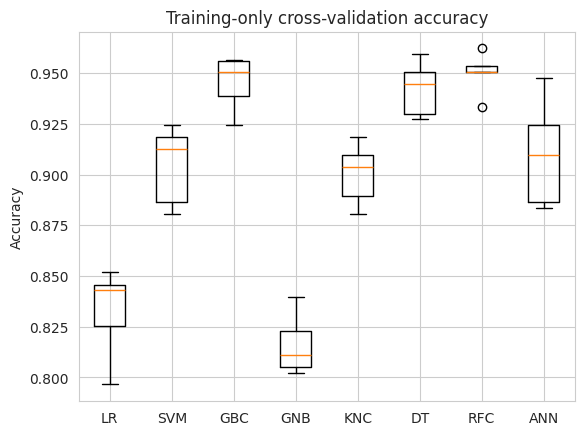

In [47]:
names = list(primary_models)

# Create a figure with a single subplot
fig, ax = plt.subplots(1, 1)

# Draw the box plots
ax.boxplot(results)

# Set the labels for each box plot
ax.set_xticklabels(names)
ax.set_ylabel("Accuracy")

# Add a title to the plot
ax.set_title('Training-only cross-validation accuracy')

# Save the figure
plt.savefig(out / 'boxplots.png')

# Show the plot
plt.show()


In [48]:
# import matplotlib.pyplot as plt
# import numpy as np

# # Define the FPR and TPR values for each algorithm as arrays
# np.array(['LRC', 'SVC', 'GBC', 'GNB', 'KNC', 'DT','RFC', 'ANN'])
# fpr = [fpr1,fpr2,fpr3,fpr4,fpr5,fpr6,fpr7,fpr8]
# tpr = [tpr1,tpr2,tpr3,tpr4,tpr5,tpr6,tpr7,tpr8]
# auc = [auc1,auc2,auc3,auc4,auc5,auc6,auc7,auc8]

# # Plot the ROC curve for each algorithm
# plt.figure(figsize=(8, 4))
# # Create plot
# for i in range(len(fpr)):
#     label_str = f"{names[i]} AUC = {auc[i]:.2f}"
#     plt.plot(fpr[i], tpr[i], label=label_str)

# # Set the axis labels and title
# plt.xlabel('False Positive Rate (FPR)')
# plt.ylabel('True Positive Rate (TPR)')
# plt.title('ROC Curve')

# # Set the axis limits
# plt.xlim([0, 1])
# plt.ylim([0, 1])

# # Add a legend
# plt.legend()

# # Show the plot
# plt.show()

In [49]:
print(selected_feature_names)

['MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL']


# ROC Curves

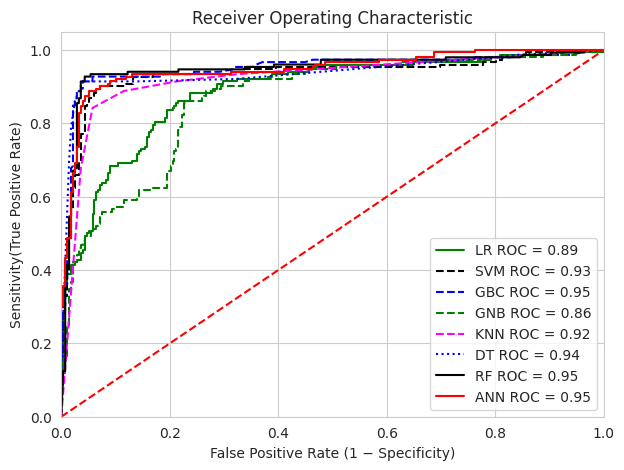

In [50]:
# Now, plot the computed values
fig = plt.figure(figsize=(7,5))

plt.plot(fpr1, tpr1, linestyle='-',color='green', label='LR ROC = %.2f' %auc1)
plt.plot(fpr2, tpr2, linestyle='--',color='black', label='SVM ROC = %.2f' %auc2)
plt.plot(fpr3, tpr3, linestyle='--',color='blue', label='GBC ROC = %.2f' %auc3)
plt.plot(fpr4, tpr4, linestyle='--',color='green', label='GNB ROC = %.2f' %auc4)
plt.plot(fpr5, tpr5, linestyle='--',color='magenta', label='KNN ROC = %.2f' %auc5)
plt.plot(fpr6, tpr6, linestyle=':',color='blue', label='DT ROC = %.2f' %auc6)
plt.plot(fpr7, tpr7, linestyle='-',color='black', label='RF ROC = %.2f' %auc7)
plt.plot(fpr8, tpr8,linestyle='-',color='red', label='ANN ROC = %.2f' %auc8)

# Custom settings for the plot
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('Sensitivity(True Positive Rate)')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.savefig(out / 'ROC_Curves.png', bbox_inches='tight')
plt.show()   # Display